In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
from scipy.cluster.hierarchy import linkage, fcluster


In [2]:
PAPER_MODE = True   # set True and re-run all cells to export figures for the paper

if PAPER_MODE:
    plt.style.use("default")                      # black text, white background
    plt.rcParams["savefig.transparent"] = True    # saved files get no background
else:
    plt.style.use("dark_background")              # white text on black, for working

These are the raw (ish) results. The jira2prov columns are derived from the names of jira issue fields changed in edits to the issue.

In [3]:
results=pd.read_csv("../results/user_activity.csv",index_col='agent')
results["total"]=results.sum(axis=1)

These fields are too granular, which makes the data very sparse and skewed. There are 35 columns, many of which are mostly zero.
There are also a lot of agents with not very much activity. Any clustering carried out on this in its current form is going to be influenced by activity levels rather than types. It is unlikely that we will see stable clusters.
Mitigation:
- inspect the jira fields that form the basis of the activity types and where the fields represent a similar type of activity, merge them into a new field
- After the merge/s, remove users with avery low levels of activity. These can be treated as their own separate 'sparse activity" cluster, and inspected for any interesting patterns:
These are the merged fields

In [4]:
issue_link = ["jira2prov:Parent", "jira2prov:ParentIssue",  "jira2prov:Link",
                  "jira2prov:ExternalissueID", "jira2prov:RemoteIssueLink"]
issue_progress = ["jira2prov:status", "jira2prov:Workflow", "jira2prov:resolution"]
categorising = ["jira2prov:labels", "jira2prov:priority", "jira2prov:issuetype"]
dev_process = ["jira2prov:FixVersion", "jira2prov:Version", "jira2prov:Component", "jira2prov:Milestone",
                   "jira2prov:Sprint"]
issue_content = ["jira2prov:description", "jira2prov:Attachment", "jira2prov:summary"]
comment_activity = ["jira2prov:comment", "jira2prov:Comment"]
merges = {"issue_link": issue_link, "issue_progress": issue_progress, "categorising": categorising,
              "dev_process": dev_process, "issue_content": issue_content, "comment_activity": comment_activity}

merged_results = results.copy()
# drop superfluous columns
merged_results=merged_results.drop(columns=['issue_comments',  'jira2prov:Rang',  'labels_issue',])

for merge in merges:
    merged_results[merge] = merged_results[merges[merge]].sum(axis=1)
    merged_results = merged_results.drop(columns=merges[merge],inplace=False)
print(merged_results.columns)
# merged_results

Index(['jira2prov:assignee', 'closed_pull', 'commits_started', 'issues_opened',
       'labels_pull', 'pr_comments', 'pull_reqs_opened',
       'referred_issue_comments', 'referred_pull_comments', 'agent_mentioned',
       'mentions_users', 'refs_issues', 'total', 'issue_link',
       'issue_progress', 'categorising', 'dev_process', 'issue_content',
       'comment_activity'],
      dtype='object')


# Data Cleaning
Separate out sparse users...


In [5]:
# separate out people with less than C contributions
C = 10
mask = merged_results["total"] >= C
sparse_contributors = merged_results[~mask]
merged_results = merged_results[mask]
merged_results=merged_results.drop(columns=['total',])



As things stand some variables are massively skewed and have large range. This will tend to cluster contributors on the volume rather than type of activity they do. To address this, we standardise the variables using row proportions. i.e. divide each variable value by the sum of its varable values. This emphasises the types of activities a contributor does over the quantity. We will also do a Square root transform, which will further improve matters by smoothing out the distribution, reducing very large values while preserving rank.

In [6]:
# transform all the data using row proprtions, so that all the variable have the same range and each column sums to 1
row_sums=merged_results.sum(axis="columns")
std_results = merged_results.div(row_sums, axis="index")
transformed_results = np.sqrt(std_results)
# transformed_results

# Clustering!
We are using agglomerative (top down merges to clusters) clustering just because...  @TODO why, by not divisive (bottom up splits)?
We can use Euclidean or bray-curtis distance.
Euclidean distance uses squared diffs and works with non-negative values. It is more sensitive to changes in magnitude.
Bray-curtis assumes non-negative values and doesn't rely on squared diffs. it is therefore less sensitive to magnitude.
The Ward method is sometime questioned when used with braycurtis. However We converted activity counts to row proportions (focus on activity profiles rather than total volume),  sqrt transformed so that Euclidean distance would provide a better measure of dissimilarity between profiles prior to hierarchical clustering.
To see the difference, change the 'metric' parameter on line 4

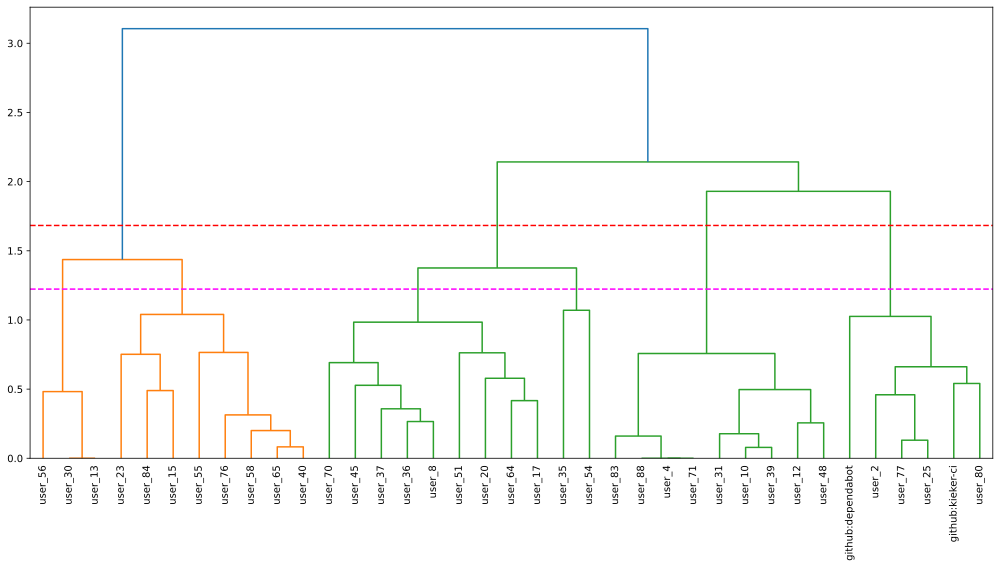

In [7]:
from scipy.cluster.hierarchy import dendrogram
from scipy.spatial.distance import pdist
# claculate (yes this is a word now!) the distances.we use bray-curtis as a distance metric because it doesnt use square values and so is less sensitive to magnitude.
e_dist = pdist(transformed_results, metric="euclidean")

# do the clustering - we are using the ward method for calculating distances between clusters. To calculate the distances between two clusters it looks at how the variance changes if the clusters are merged.
clusters = linkage(e_dist, method="ward")

# make Jupyter display the preview  as a vector - this wont display in the IDE and we only need it when saving- set it back to png to display
%config InlineBackend.figure_format = 'svg'

plt.figure(figsize=(14, 8))
# make a tree
tree = dendrogram(clusters, labels=transformed_results.index.tolist(), leaf_rotation=90, leaf_font_size=10)

# reorder dataframe rows to match dendrogram leaf order
ordered_results = transformed_results.iloc[tree["leaves"]]

# reorder the column variables to group them into meaningful groups--
variables_order = [
                # issue and PR progressing, dev workflows
                    'pull_reqs_opened',
                    'closed_pull',
                    'jira2prov:assignee',   # from here down to 'issue_link' it's jira2prov /issue related, so pre-Git users should go dark in this region
                    'dev_process',
                    'issues_opened' ,       #   |
                    'issue_progress',       #   |
                    'issue_content',        #   |
                    'refs_issues',          #   |
                    'issue_link',           #       end of the issue related region
                #categorising, content labelling
                    'categorising',
                    'labels_pull',
                #communicating, referencing
                    'referred_pull_comments',
                    'mentions_users',
                #commenting
                    'pr_comments',
                    'comment_activity',
                #being referred to
                    'agent_mentioned',
                # writing code
                    'commits_started',
                ]

# reorder the variables to group them by similarity for a better heatmap
ordered_results =  ordered_results[variables_order]
MAIN_CLUSTER_COLOUR = 'red'
SUB_CLUSTER_COLOUR = 'magenta'
plt.axhline(y=1.683, color=MAIN_CLUSTER_COLOUR, linestyle="--")
plt.axhline(y=1.223, color=SUB_CLUSTER_COLOUR, linestyle="--")
plt.tight_layout()

# uncomment this and line 10 to save it as a vector pdf
plt.savefig('dendrogram.pdf', format='pdf', bbox_inches='tight', transparent=True )
plt.show()

# Heatmap
This heatmap has users arranged on the Y-Axis in the same order as the leaves on the dendrogram. This means users are grouped together by similarity, so we get a visual representation of which activities they are grouped by.

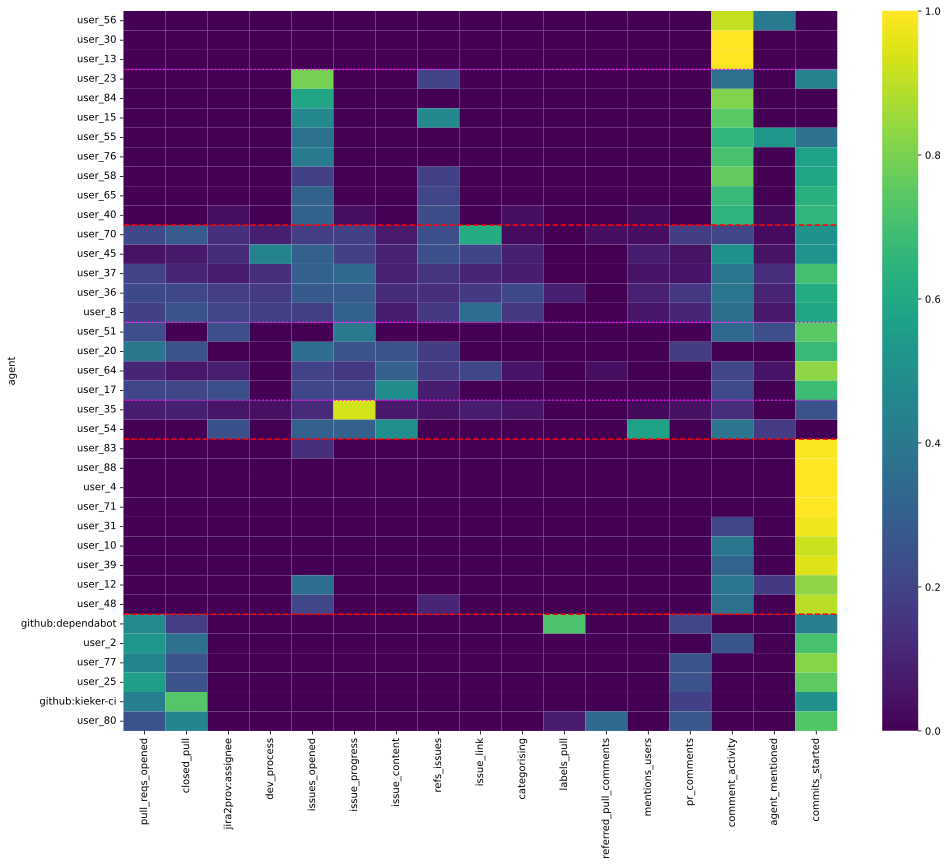

In [8]:
# heatmap using data with the agents in the same order as the dendrogram leaves, i.e
plt.figure(figsize=(16, 13))
# ...using the ordered results from the last cell.
hmp=sns.heatmap(ordered_results, cmap="viridis",yticklabels=1,xticklabels=1)
hmp.axhline(3, color=SUB_CLUSTER_COLOUR, linestyle="dotted")
hmp.axhline(11, color=MAIN_CLUSTER_COLOUR, linestyle="--")
hmp.axhline(16, color=SUB_CLUSTER_COLOUR, linestyle="dotted")
hmp.axhline(20, color=SUB_CLUSTER_COLOUR, linestyle="dotted")
hmp.axhline(22, color=MAIN_CLUSTER_COLOUR, linestyle="--")
hmp.axhline(31, color=MAIN_CLUSTER_COLOUR, linestyle="--")
hmp.axhline(39, color=MAIN_CLUSTER_COLOUR, linestyle="--")
# print (ordered_results.index.tolist())
plt.savefig('heatmap.pdf', format='pdf', bbox_inches='tight')
plt.show()

# merge heights
Look for the "elbow" that tells us where the best cut would be.
There are two candidates.
  - The red line gives us 6 clusters
  - The yellow line gives us 4
The red elbow is the most pronounced and also generates clusters that are better separated and aligned with the heatmap

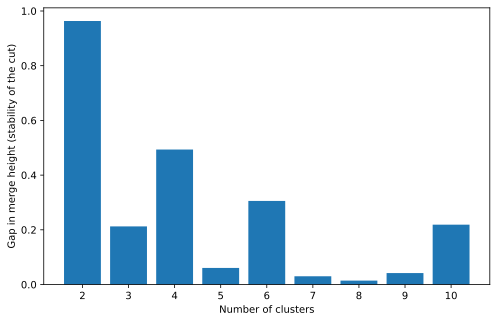

k=2: gap 0.963, cut at 2.624
k=3: gap 0.212, cut at 2.036
k=4: gap 0.493, cut at 1.683
k=5: gap 0.061, cut at 1.406
k=6: gap 0.306, cut at 1.223
k=7: gap 0.030, cut at 1.055
k=8: gap 0.014, cut at 1.033
k=9: gap 0.042, cut at 1.005
k=10: gap 0.219, cut at 0.875


In [9]:
# merge_heights=clusters[:,2]
# sorted_merge_heights=sorted(merge_heights)
# plt.figure(figsize=(16, 13))
# plt.axhline(y=1.6, color="red", linestyle="--")
# plt.axhline(y=0.77, color="yellow", linestyle="--")
# plt.plot(sorted_merge_heights)
merge_heights = clusters[:, 2]
heights_descending = np.sort(merge_heights)[::-1]

# gap available for each number of clusters k: the range of cut heights that gives exactly k clusters
max_clusters = 10
cluster_counts = np.arange(2, max_clusters + 1)
gap_sizes = heights_descending[cluster_counts - 2] - heights_descending[cluster_counts - 1]
cut_midpoints = (heights_descending[cluster_counts - 2] + heights_descending[cluster_counts - 1]) / 2

plt.figure(figsize=(8, 5))
plt.bar(cluster_counts, gap_sizes)
plt.xlabel("Number of clusters")
plt.ylabel("Gap in merge height (stability of the cut)")
plt.xticks(cluster_counts)
plt.savefig('gapHeight.pdf', format='pdf', bbox_inches='tight')
plt.show()

for k, gap, midpoint in zip(cluster_counts, gap_sizes, cut_midpoints):
    print(f"k={k}: gap {gap:.3f}, cut at {midpoint:.3f}")


So let's generate our actual cluster memberships...

In [10]:
from scipy.cluster.hierarchy import fcluster
cut_height = 1.683
cluster_labels = fcluster(clusters, t=cut_height, criterion="distance")
cluster_results_df = transformed_results.copy()
cluster_results_df["cluster"] = cluster_labels
c = cluster_results_df["cluster"]
# cluster_results_df
c.to_csv("cluster_membership1.csv")


In [11]:
cluster_profiles = cluster_results_df.groupby("cluster").mean(numeric_only=True)
# print(cluster_profiles)
# cluster_profiles
# cluster_profiles.to_csv('clusterProfiles.csv')

### Investigating the temporal drivers for each Cluster
To assess the extent to which these clusters are driven by the activity dates of their members we will first calculate some temporal cluster centroids i.e. the date at the centre of the total activity period of the individuals in that cluster

In [12]:
from kieker_analysis.stats.agent_dates import agent_dates

raw_dates = pd.read_csv("cluster_dates_new.csv")
dates_by_agent = agent_dates(raw_dates).set_index("agent")
cluster_dates = dates_by_agent.join(c.rename("cluster"), how="inner").reset_index()

print("clustered but no dates:", sorted(set(c.index) - set(dates_by_agent.index)))
cluster_dates.to_csv("cluster_dates_oct26.csv", index=False)

clustered but no dates: []


In [13]:
from scipy import stats
# I ran this on the graphdb workbench.
df = pd.read_csv("cluster_dates_oct26.csv")
cluster_column="cluster"
# format the dates
df["start_date"] = pd.to_datetime(df["start_date"],format="%Y-%m-%d")
df["end_date"]   = pd.to_datetime(df["end_date"],format="%Y-%m-%d")
# Get the date at which time begins. I can actually remember a time before this but it cannot have been. I was clearly dreaming and have not yet turned 60...
epoch = pd.Timestamp("1970-01-01")
# get the number of days there has been up to the start date
df["start_days"]    = (df["start_date"] - epoch).dt.days
#  get the number of days there has been up to the end date
df["end_days"]      = (df["end_date"]   - epoch).dt.days
# calculate the length of time active in days

#  get the middle day ('centroid') by calculating the length of the time active and eviding by two
df["centroid_days"] = (df["start_days"] + df["end_days"]) / 2

# now for a bit of the old Kruskal-wallis - this is non-parametric equivalent to ANOVA. We use it both because we are working with medians (a date centroid) and because the cluster data violates ANOVA assumptions of normality.

# get the cluster names/ids
cluster_ids   = sorted(df[cluster_column].unique())
grouped_cents = [df.loc[df[cluster_column] == c, "centroid_days"].values for c in cluster_ids]

kw_stat, kw_p = stats.kruskal(*grouped_cents)

print("=" * 70)
print("KRUSKAL-WALLIS TEST: do clusters differ in temporal centroid?")
print(f"  H = {kw_stat:.3f},  p = {kw_p:.4e}")
if kw_p < 0.05:
    print("  ✓ Significant — clusters are temporally separated.")
else:
    print("  ✗ Not significant — no strong temporal driver detected.")
print("=" * 70)

KRUSKAL-WALLIS TEST: do clusters differ in temporal centroid?
  H = 22.592,  p = 4.9120e-05
  ✓ Significant — clusters are temporally separated.


## pairwise mann-whitney U

In [14]:
from itertools import combinations
from scipy.stats import mannwhitneyu

pairs     = list(combinations(cluster_ids, 2))
n_tests   = len(pairs)
alpha_adj_b = 0.05 / n_tests   # Bonferroni threshold
alpha_adj = 0.05

results = []
for c1, c2 in pairs:
    a = df.loc[df[cluster_column] == c1, "centroid_days"].values
    b = df.loc[df[cluster_column] == c2, "centroid_days"].values
    u_stat, p_val = mannwhitneyu(a, b, alternative="two-sided")
    results.append({
        "Cluster A": c1,
        "Cluster B": c2,
        "U stat": round(u_stat, 1),
        "p-val": p_val,
        "significant*": "Yes" if p_val < alpha_adj_b else "No",
        "significant": "Yes" if p_val < alpha_adj else "No",
    })

results_df = pd.DataFrame(results)
results_df["p-val"] = results_df["p-val"].map(lambda x: f"{x:.4e}")

print(f"\npairwise mann-whitney U  (bonferroni cf = {alpha_adj:.4f})")
print(results_df.to_string(index=False, ))
print("  * Significant after bonferroni correction\n")


pairwise mann-whitney U  (bonferroni cf = 0.0500)
 Cluster A  Cluster B  U stat      p-val significant* significant
         1          2     0.0 8.1515e-05          Yes         Yes
         1          3    46.0 8.1971e-01           No          No
         1          4     0.0 1.6160e-04          Yes         Yes
         2          3    85.0 7.8354e-03          Yes         Yes
         2          4    16.0 9.8255e-02           No          No
         3          4     4.0 4.7952e-03          Yes         Yes
  * Significant after bonferroni correction



## Kernel Density plots


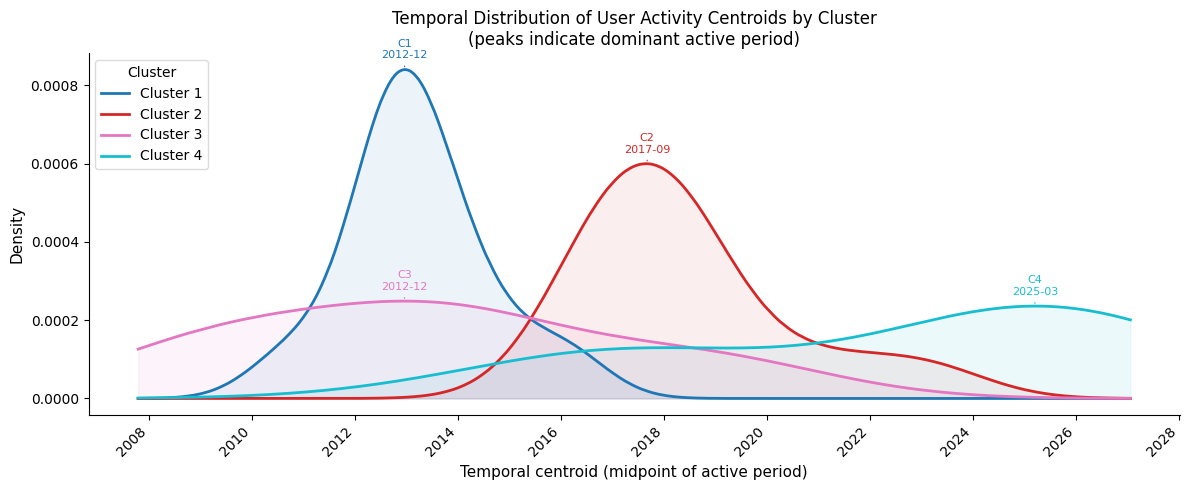

In [15]:
import matplotlib.dates as mdates


def days_to_ts(days_array):
    return [epoch + pd.Timedelta(days=int(d)) for d in days_array]

# get some colours from matplotlibs colour pallette one for each cluster
colours = plt.cm.tab10(np.linspace(0, 0.9, len(cluster_ids)))

fig, ax = plt.subplots(figsize=(12, 5))
days=None
for colour, cid in zip(colours, cluster_ids):
    days = df.loc[df[cluster_column] == cid, "centroid_days"].values

    kde    = stats.gaussian_kde(days, bw_method="scott")
    x_days = np.linspace(df["centroid_days"].min() - 365,
                         df["centroid_days"].max() + 365, 500)
    y      = kde(x_days)
    x_ts   = days_to_ts(x_days)

    ax.plot(x_ts, y, label=f"Cluster {cid}", color=colour, linewidth=2)
    ax.fill_between(x_ts, y, alpha=0.08, color=colour)

    # Annotate peak date
    peak_idx  = np.argmax(y)
    peak_date = x_ts[peak_idx]
    ax.annotate(
        f"C{cid}\n{peak_date.strftime('%Y-%m')}",
        xy=(peak_date, y[peak_idx]),
        xytext=(0, 8), textcoords="offset points",
        ha="center", fontsize=8, color=colour,
        arrowprops=dict(arrowstyle="-", color=colour, lw=0.8),
    )

ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

ax.set_xlabel("Temporal centroid (midpoint of active period)", fontsize=11)
ax.set_ylabel("Density", fontsize=11)
ax.set_title("Temporal Distribution of User Activity Centroids by Cluster\n"
             "(peaks indicate dominant active period)", fontsize=12)
ax.legend(title="Cluster", loc="upper left", framealpha=0.7)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
out_path = "temporal_6cluster_kde.pdf"

# make Jupyter display the preview  as a vector - this wont display in the IDE and we only need it when saving- set it back to png to display
%config InlineBackend.figure_format = 'png'
# plt.savefig(out_path, dpi=150)
# print(f"KDE plot saved → {out_path}")
plt.plot
plt.savefig('kde.pdf', format='pdf', bbox_inches='tight')
plt.show()